In [1]:
from pathlib import Path

import geopandas as gpd
import rasterio
import numpy as np
import folium

# Project paths
project_dir = Path(r"C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project")

lst_path = project_dir / "outputs" / "rasters" / "Riyadh_LST_2026_Celsius.tif"
boundary_path = project_dir / "Data" / "boundary" / "Riyadh_Urban_Boundary.gpkg"

print("LST raster exists:", lst_path.exists())
print("Riyadh boundary exists:", boundary_path.exists())
print("Folium version:", folium.__version__)

LST raster exists: True
Riyadh boundary exists: True
Folium version: 0.20.0


In [2]:
# Load Riyadh boundary
riyadh_boundary = gpd.read_file(boundary_path)

# Reproject boundary to WGS84 for web mapping
riyadh_boundary_wgs84 = riyadh_boundary.to_crs(epsg=4326)

# Read LST raster metadata
with rasterio.open(lst_path) as src:
    lst = src.read(1).astype("float32")
    lst_crs = src.crs
    lst_bounds = src.bounds
    lst_nodata = src.nodata

# Convert nodata values to NaN
if lst_nodata is not None:
    lst[lst == lst_nodata] = np.nan

print("Boundary CRS:", riyadh_boundary_wgs84.crs)
print("LST CRS:", lst_crs)
print("LST shape:", lst.shape)
print("Valid LST range:", round(float(np.nanmin(lst)), 2), "to", round(float(np.nanmax(lst)), 2), "°C")

Boundary CRS: EPSG:4326
LST CRS: EPSG:32638
LST shape: (1453, 1555)
Valid LST range: 23.34 to 62.28 °C


Interactive LST map saved to:
C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project\website\assets\maps\Riyadh_LST_Interactive.html



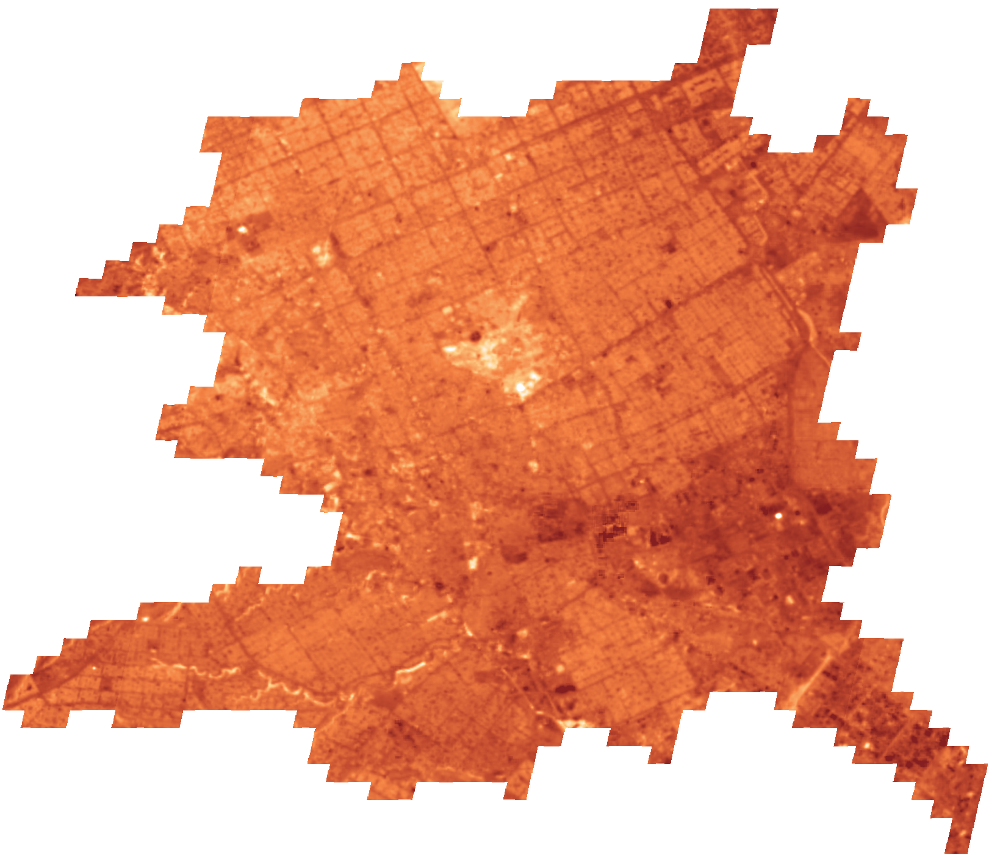

In [2]:
from pathlib import Path

import geopandas as gpd
import rasterio
import numpy as np
import folium
import branca.colormap as bcm

from rasterio.warp import calculate_default_transform, reproject, Resampling
from matplotlib.colors import LinearSegmentedColormap, Normalize
from folium import MacroElement
from jinja2 import Template

# ---------------------------------------------------------
# Project paths
# ---------------------------------------------------------

project_dir = Path(
    r"C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project"
)

lst_path = (
    project_dir
    / "outputs"
    / "rasters"
    / "Riyadh_LST_2026_Celsius.tif"
)

boundary_path = (
    project_dir
    / "Data"
    / "boundary"
    / "Riyadh_Urban_Boundary.gpkg"
)

lst_html_path = (
    project_dir
    / "website"
    / "assets"
    / "maps"
    / "Riyadh_LST_Interactive.html"
)

lst_html_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

# ---------------------------------------------------------
# Load Riyadh boundary
# ---------------------------------------------------------

riyadh_boundary = gpd.read_file(boundary_path)
riyadh_boundary_wgs84 = riyadh_boundary.to_crs(epsg=4326)

# ---------------------------------------------------------
# Read LST raster
# ---------------------------------------------------------

with rasterio.open(lst_path) as src:
    lst = src.read(1).astype("float32")
    lst_crs = src.crs
    lst_transform_original = src.transform
    lst_nodata = src.nodata
    lst_bounds_original = src.bounds

if lst_nodata is not None:
    lst[lst == lst_nodata] = np.nan

# ---------------------------------------------------------
# Reproject LST raster to WGS84
# ---------------------------------------------------------

dst_crs = "EPSG:4326"

transform, width, height = calculate_default_transform(
    lst_crs,
    dst_crs,
    lst.shape[1],
    lst.shape[0],
    *lst_bounds_original
)

lst_wgs84 = np.full(
    (height, width),
    np.nan,
    dtype="float32"
)

reproject(
    source=lst,
    destination=lst_wgs84,
    src_transform=lst_transform_original,
    src_crs=lst_crs,
    dst_transform=transform,
    dst_crs=dst_crs,
    src_nodata=np.nan,
    dst_nodata=np.nan,
    resampling=Resampling.bilinear
)

# ---------------------------------------------------------
# Create Folium image bounds
# ---------------------------------------------------------

west = transform.c
north = transform.f
east = west + transform.a * width
south = north + transform.e * height

image_bounds = [
    [south, west],
    [north, east]
]

# ---------------------------------------------------------
# Heat color palette
# ---------------------------------------------------------

heat_colors = [
    "#F4EFE5",
    "#F2C078",
    "#E9783C",
    "#B8452A",
    "#7F1D1D"
]

heat_cmap = LinearSegmentedColormap.from_list(
    "riyadh_heat",
    heat_colors
)

vmin = 40
vmax = 58

norm = Normalize(
    vmin=vmin,
    vmax=vmax,
    clip=True
)

rgba = heat_cmap(
    norm(lst_wgs84)
)

rgba[..., 3] = np.where(
    np.isfinite(lst_wgs84),
    0.80,
    0.0
)

# ---------------------------------------------------------
# Map center
# ---------------------------------------------------------

center = riyadh_boundary_wgs84.geometry.union_all().centroid

# ---------------------------------------------------------
# Build interactive map
# ---------------------------------------------------------

lst_map = folium.Map(
    location=[center.y, center.x],
    zoom_start=10,
    tiles="OpenStreetMap",
    control_scale=True
)

# ---------------------------------------------------------
# LST raster overlay
# ---------------------------------------------------------

folium.raster_layers.ImageOverlay(
    image=rgba,
    bounds=image_bounds,
    opacity=1,
    name="Land Surface Temperature",
    interactive=True,
    cross_origin=False,
    zindex=1
).add_to(lst_map)

# ---------------------------------------------------------
# Riyadh boundary
# ---------------------------------------------------------

folium.GeoJson(
    riyadh_boundary_wgs84,
    name="Riyadh Urban Boundary",
    style_function=lambda feature: {
        "color": "#7F1D1D",
        "weight": 2.5,
        "fillOpacity": 0
    }
).add_to(lst_map)

# ---------------------------------------------------------
# Temperature legend
# ---------------------------------------------------------

legend = bcm.LinearColormap(
    colors=heat_colors,
    vmin=vmin,
    vmax=vmax,
    caption="Land Surface Temperature (°C)"
)

legend.add_to(lst_map)

# ---------------------------------------------------------
# Styled click popup
# ---------------------------------------------------------

class LSTStyledPopup(MacroElement):

    def __init__(self, raster_array, transform):
        super().__init__()

        self._name = "LSTStyledPopup"

        self.raster_data = np.where(
            np.isfinite(raster_array),
            np.round(raster_array, 2),
            None
        ).tolist()

        self.west = transform.c
        self.north = transform.f
        self.pixel_width = transform.a
        self.pixel_height = transform.e
        self.rows = raster_array.shape[0]
        self.cols = raster_array.shape[1]

        self._template = Template("""
        {% macro script(this, kwargs) %}

        const lstRaster = {{ this.raster_data | tojson }};

        const west = {{ this.west }};
        const north = {{ this.north }};
        const pixelWidth = {{ this.pixel_width }};
        const pixelHeight = {{ this.pixel_height }};
        const rows = {{ this.rows }};
        const cols = {{ this.cols }};

        {{ this._parent.get_name() }}.on('click', function(e) {

            const lon = e.latlng.lng;
            const lat = e.latlng.lat;

            const col = Math.floor((lon - west) / pixelWidth);
            const row = Math.floor((lat - north) / pixelHeight);

            if (
                row >= 0 &&
                row < rows &&
                col >= 0 &&
                col < cols
            ) {

                const value = lstRaster[row][col];

                if (value !== null) {

                    let category = "Moderate Surface Temperature";

                    if (value >= 55) {
                        category = "Very High Surface Temperature";
                    } else if (value >= 52) {
                        category = "High Surface Temperature";
                    } else if (value >= 48) {
                        category = "Moderate Surface Temperature";
                    } else {
                        category = "Lower Surface Temperature";
                    }

                    const html = `
                        <div style="
                            font-family: Arial, sans-serif;
                            min-width: 240px;
                            background: #FAF7F0;
                            border: 1px solid #E9783C;
                            border-radius: 12px;
                            padding: 14px 16px;
                            color: #2B2B2B;
                            box-shadow: 0 8px 20px rgba(127, 29, 29, 0.18);
                        ">

                            <div style="
                                font-size: 16px;
                                font-weight: 700;
                                color: #7F1D1D;
                                margin-bottom: 10px;
                                padding-bottom: 7px;
                                border-bottom: 2px solid #E9783C;
                            ">
                                Land Surface Temperature
                            </div>

                            <div style="
                                line-height: 1.65;
                                font-size: 13px;
                            ">

                                <div>
                                    <span style="
                                        font-weight: 600;
                                        color: #B8452A;
                                    ">
                                        Surface Temperature
                                    </span><br>
                                    ${value.toFixed(1)} °C
                                </div>

                                <div style="margin-top:8px;">
                                    <span style="
                                        font-weight: 600;
                                        color: #B8452A;
                                    ">
                                        Thermal Level
                                    </span><br>
                                    ${category}
                                </div>

                            </div>

                        </div>
                    `;

                    L.popup({
                        maxWidth: 330,
                        className: "lst-custom-popup"
                    })
                    .setLatLng(e.latlng)
                    .setContent(html)
                    .openOn({{ this._parent.get_name() }});

                }

            }

        });

        {% endmacro %}
        """)

LSTStyledPopup(
    raster_array=lst_wgs84,
    transform=transform
).add_to(lst_map)

# ---------------------------------------------------------
# Layer control
# ---------------------------------------------------------

folium.LayerControl(
    collapsed=False
).add_to(lst_map)

# ---------------------------------------------------------
# Fit map to Riyadh
# ---------------------------------------------------------

minx, miny, maxx, maxy = riyadh_boundary_wgs84.total_bounds

lst_map.fit_bounds([
    [miny, minx],
    [maxy, maxx]
])

# ---------------------------------------------------------
# Save updated interactive map
# ---------------------------------------------------------

lst_map.save(lst_html_path)

print("Interactive LST map saved to:")
print(lst_html_path)

# ---------------------------------------------------------
# Display
# ---------------------------------------------------------

lst_map

Interactive NDVI map saved to:
C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project\website\assets\maps\Riyadh_NDVI_Interactive.html



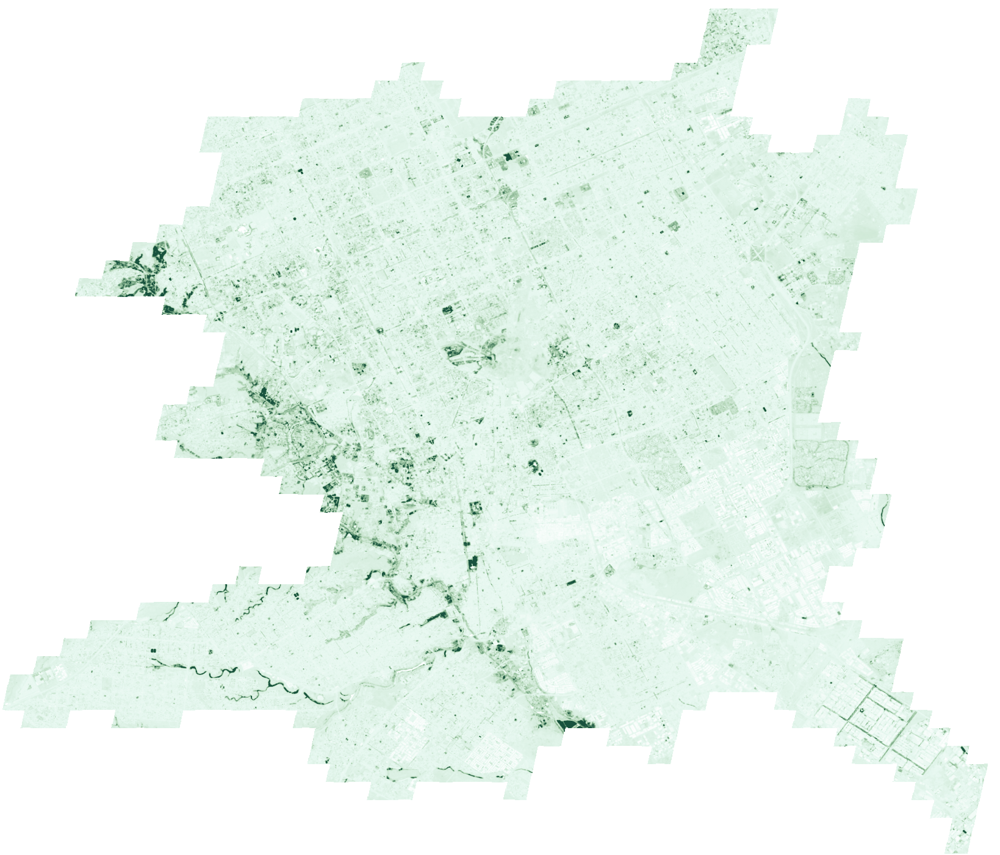

In [9]:
from pathlib import Path

import geopandas as gpd
import rasterio
import numpy as np
import folium
import branca.colormap as bcm

from rasterio.warp import calculate_default_transform, reproject, Resampling
from matplotlib.colors import LinearSegmentedColormap, Normalize
from folium import MacroElement
from jinja2 import Template

# ---------------------------------------------------------
# Project paths
# ---------------------------------------------------------

project_dir = Path(
    r"C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project"
)

ndvi_path = (
    project_dir
    / "outputs"
    / "rasters"
    / "Riyadh_NDVI_2026.tif"
)

boundary_path = (
    project_dir
    / "Data"
    / "boundary"
    / "Riyadh_Urban_Boundary.gpkg"
)

ndvi_html_path = (
    project_dir
    / "website"
    / "assets"
    / "maps"
    / "Riyadh_NDVI_Interactive.html"
)

ndvi_html_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

# ---------------------------------------------------------
# Load Riyadh boundary
# ---------------------------------------------------------

riyadh_boundary = gpd.read_file(boundary_path)
riyadh_boundary_wgs84 = riyadh_boundary.to_crs(epsg=4326)

# ---------------------------------------------------------
# Read NDVI raster
# ---------------------------------------------------------

with rasterio.open(ndvi_path) as src:
    ndvi = src.read(1).astype("float32")
    ndvi_crs = src.crs
    ndvi_transform_original = src.transform
    ndvi_nodata = src.nodata
    ndvi_bounds_original = src.bounds

if ndvi_nodata is not None:
    ndvi[ndvi == ndvi_nodata] = np.nan

# ---------------------------------------------------------
# Reproject NDVI raster to WGS84
# ---------------------------------------------------------

dst_crs = "EPSG:4326"

transform, width, height = calculate_default_transform(
    ndvi_crs,
    dst_crs,
    ndvi.shape[1],
    ndvi.shape[0],
    *ndvi_bounds_original
)

ndvi_wgs84 = np.full(
    (height, width),
    np.nan,
    dtype="float32"
)

reproject(
    source=ndvi,
    destination=ndvi_wgs84,
    src_transform=ndvi_transform_original,
    src_crs=ndvi_crs,
    dst_transform=transform,
    dst_crs=dst_crs,
    src_nodata=np.nan,
    dst_nodata=np.nan,
    resampling=Resampling.bilinear
)

# ---------------------------------------------------------
# Create Folium image bounds
# ---------------------------------------------------------

west = transform.c
north = transform.f
east = west + transform.a * width
south = north + transform.e * height

image_bounds = [
    [south, west],
    [north, east]
]

# ---------------------------------------------------------
# NDVI color palette
# ---------------------------------------------------------

ndvi_colors = [
    "#F4EFE5",
    "#DCE8D7",
    "#ABC8A4",
    "#6F9A74",
    "#174D38"
]

ndvi_cmap = LinearSegmentedColormap.from_list(
    "riyadh_ndvi",
    ndvi_colors
)

vmin = -0.05
vmax = 0.40

norm = Normalize(
    vmin=vmin,
    vmax=vmax,
    clip=True
)

rgba = ndvi_cmap(
    norm(ndvi_wgs84)
)

rgba[..., 3] = np.where(
    np.isfinite(ndvi_wgs84),
    0.80,
    0.0
)

# ---------------------------------------------------------
# Map center
# ---------------------------------------------------------

center = riyadh_boundary_wgs84.geometry.union_all().centroid

# ---------------------------------------------------------
# Build interactive map
# ---------------------------------------------------------

ndvi_map = folium.Map(
    location=[center.y, center.x],
    zoom_start=10,
    tiles="OpenStreetMap",
    control_scale=True
)

# ---------------------------------------------------------
# NDVI raster overlay
# ---------------------------------------------------------

folium.raster_layers.ImageOverlay(
    image=rgba,
    bounds=image_bounds,
    opacity=1,
    name="Vegetation Presence",
    interactive=True,
    cross_origin=False,
    zindex=1
).add_to(ndvi_map)

# ---------------------------------------------------------
# Riyadh boundary
# ---------------------------------------------------------

folium.GeoJson(
    riyadh_boundary_wgs84,
    name="Riyadh Urban Boundary",
    style_function=lambda feature: {
        "color": "#174D38",
        "weight": 2.5,
        "fillOpacity": 0
    }
).add_to(ndvi_map)

# ---------------------------------------------------------
# Vegetation legend
# ---------------------------------------------------------

legend = bcm.LinearColormap(
    colors=ndvi_colors,
    vmin=vmin,
    vmax=vmax,
    caption="Vegetation Presence (NDVI)"
)

legend.add_to(ndvi_map)

# ---------------------------------------------------------
# Styled click-to-read NDVI popup
# ---------------------------------------------------------

class NDVIStyledPopup(MacroElement):

    def __init__(self, raster_array, transform):
        super().__init__()

        self._name = "NDVIStyledPopup"

        self.raster_data = np.where(
            np.isfinite(raster_array),
            np.round(raster_array, 3),
            None
        ).tolist()

        self.west = transform.c
        self.north = transform.f
        self.pixel_width = transform.a
        self.pixel_height = transform.e
        self.rows = raster_array.shape[0]
        self.cols = raster_array.shape[1]

        self._template = Template("""
        {% macro script(this, kwargs) %}

        const ndviRaster = {{ this.raster_data | tojson }};

        const west = {{ this.west }};
        const north = {{ this.north }};
        const pixelWidth = {{ this.pixel_width }};
        const pixelHeight = {{ this.pixel_height }};
        const rows = {{ this.rows }};
        const cols = {{ this.cols }};

        {{ this._parent.get_name() }}.on('click', function(e) {

            const lon = e.latlng.lng;
            const lat = e.latlng.lat;

            const col = Math.floor((lon - west) / pixelWidth);
            const row = Math.floor((lat - north) / pixelHeight);

            if (
                row >= 0 &&
                row < rows &&
                col >= 0 &&
                col < cols
            ) {

                const value = ndviRaster[row][col];

                if (value !== null) {

                    let category = "Very Low Vegetation Presence";

                    if (value >= 0.30) {
                        category = "High Vegetation Presence";
                    } else if (value >= 0.20) {
                        category = "Moderate Vegetation Presence";
                    } else if (value >= 0.10) {
                        category = "Low Vegetation Presence";
                    }

                    const html = `
                        <div style="
                            font-family: Arial, sans-serif;
                            min-width: 240px;
                            background: #FAF7F0;
                            border: 1px solid #86A994;
                            border-radius: 12px;
                            padding: 14px 16px;
                            color: #2B2B2B;
                            box-shadow: 0 8px 20px rgba(23, 77, 56, 0.18);
                        ">

                            <div style="
                                font-size: 16px;
                                font-weight: 700;
                                color: #174D38;
                                margin-bottom: 10px;
                                padding-bottom: 7px;
                                border-bottom: 2px solid #86A994;
                            ">
                                Vegetation Presence
                            </div>

                            <div style="
                                line-height: 1.65;
                                font-size: 13px;
                            ">

                                <div>
                                    <span style="
                                        font-weight: 600;
                                        color: #6F9A74;
                                    ">
                                        NDVI
                                    </span><br>
                                    ${value.toFixed(3)}
                                </div>

                                <div style="margin-top:8px;">
                                    <span style="
                                        font-weight: 600;
                                        color: #6F9A74;
                                    ">
                                        Vegetation Level
                                    </span><br>
                                    ${category}
                                </div>

                            </div>

                        </div>
                    `;

                    L.popup({
                        maxWidth: 330,
                        className: "ndvi-custom-popup"
                    })
                    .setLatLng(e.latlng)
                    .setContent(html)
                    .openOn({{ this._parent.get_name() }});

                }

            }

        });

        {% endmacro %}
        """)

NDVIStyledPopup(
    raster_array=ndvi_wgs84,
    transform=transform
).add_to(ndvi_map)

# ---------------------------------------------------------
# Layer control
# ---------------------------------------------------------

folium.LayerControl(
    collapsed=False
).add_to(ndvi_map)

# ---------------------------------------------------------
# Fit map to Riyadh
# ---------------------------------------------------------

minx, miny, maxx, maxy = riyadh_boundary_wgs84.total_bounds

ndvi_map.fit_bounds([
    [miny, minx],
    [maxy, maxx]
])

# ---------------------------------------------------------
# Save updated interactive map
# ---------------------------------------------------------

ndvi_map.save(ndvi_html_path)

print("Interactive NDVI map saved to:")
print(ndvi_html_path)

# ---------------------------------------------------------
# Display
# ---------------------------------------------------------

ndvi_map

In [8]:
from pathlib import Path

import geopandas as gpd
import folium
import branca.colormap as cm

from folium import MacroElement
from jinja2 import Template

# ---------------------------------------------------------
# Project paths
# ---------------------------------------------------------

project_dir = Path(
    r"C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project"
)

building_grid_path = (
    project_dir
    / "Data"
    / "building_footprints"
    / "Riyadh_500m_Grid_Building_Metrics.gpkg"
)

boundary_path = (
    project_dir
    / "Data"
    / "boundary"
    / "Riyadh_Urban_Boundary.gpkg"
)

building_html_path = (
    project_dir
    / "website"
    / "assets"
    / "maps"
    / "Riyadh_Building_Coverage_Interactive.html"
)

building_html_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

# ---------------------------------------------------------
# Load data
# ---------------------------------------------------------

building_grid = gpd.read_file(building_grid_path)
riyadh_boundary = gpd.read_file(boundary_path)

building_grid = building_grid.to_crs(epsg=4326)
riyadh_boundary = riyadh_boundary.to_crs(epsg=4326)

# ---------------------------------------------------------
# Keep required fields
# ---------------------------------------------------------

building_grid = building_grid[
    [
        "grid_id",
        "building_count",
        "building_area_m2",
        "building_coverage_pct",
        "geometry"
    ]
].copy()

# ---------------------------------------------------------
# Clean values
# ---------------------------------------------------------

building_grid["grid_id"] = building_grid["grid_id"].astype(str)

building_grid["building_count"] = (
    building_grid["building_count"]
    .fillna(0)
    .round(0)
    .astype(int)
)

building_grid["building_area_m2"] = (
    building_grid["building_area_m2"]
    .fillna(0)
    .round(0)
)

building_grid["building_coverage_pct"] = (
    building_grid["building_coverage_pct"]
    .fillna(0)
    .round(1)
)

# ---------------------------------------------------------
# Coverage categories
# ---------------------------------------------------------

def coverage_category(value):
    if value < 10:
        return "Very Low Building Coverage"
    elif value < 20:
        return "Low Building Coverage"
    elif value < 30:
        return "Moderate Building Coverage"
    elif value < 40:
        return "High Building Coverage"
    else:
        return "Very High Building Coverage"

building_grid["coverage_category"] = (
    building_grid["building_coverage_pct"]
    .apply(coverage_category)
)

# ---------------------------------------------------------
# Create map
# ---------------------------------------------------------

center = riyadh_boundary.geometry.union_all().centroid

building_map = folium.Map(
    location=[center.y, center.x],
    zoom_start=10,
    tiles="OpenStreetMap",
    control_scale=True
)

# ---------------------------------------------------------
# Color scale
# ---------------------------------------------------------

coverage_colors = [
    "#F4EFE5",
    "#EAE1CF",
    "#CDBF9B",
    "#9B895C",
    "#5A4B2F"
]

coverage_cmap = cm.LinearColormap(
    colors=coverage_colors,
    vmin=0,
    vmax=70
)

coverage_cmap.caption = "Building Coverage (%)"

# ---------------------------------------------------------
# Add Riyadh boundary first
# ---------------------------------------------------------

folium.GeoJson(
    data=riyadh_boundary,
    name="Riyadh Urban Boundary",
    style_function=lambda feature: {
        "color": "#174D38",
        "weight": 2.5,
        "fillOpacity": 0
    }
).add_to(building_map)

# ---------------------------------------------------------
# Building grid
# ---------------------------------------------------------

building_layer = folium.GeoJson(
    data=building_grid,
    name="Building Coverage",
    style_function=lambda feature: {
        "fillColor": coverage_cmap(
            feature["properties"]["building_coverage_pct"]
        ),
        "color": "#9A8A68",
        "weight": 0.25,
        "fillOpacity": 0.78
    },
    highlight_function=lambda feature: {
        "color": "#5A4B2F",
        "weight": 1.8,
        "fillOpacity": 0.95
    }
).add_to(building_map)

# ---------------------------------------------------------
# Custom styled click popup
# ---------------------------------------------------------

class BuildingStyledPopup(MacroElement):

    def __init__(self, geojson_layer):
        super().__init__()

        self._name = "BuildingStyledPopup"
        self.geojson_name = geojson_layer.get_name()

        self._template = Template("""
        {% macro script(this, kwargs) %}

        {{ this.geojson_name }}.eachLayer(function(layer) {

            layer.on("click", function(e) {

                const p = layer.feature.properties;

                const html = `
                    <div style="
                        font-family: Arial, sans-serif;
                        min-width: 245px;
                        background: #FAF7F0;
                        border: 1px solid #C5A45A;
                        border-radius: 12px;
                        padding: 14px 16px;
                        color: #2B2B2B;
                        box-shadow: 0 8px 20px rgba(90, 75, 47, 0.18);
                    ">

                        <div style="
                            font-size: 16px;
                            font-weight: 700;
                            color: #5A4B2F;
                            margin-bottom: 10px;
                            padding-bottom: 7px;
                            border-bottom: 2px solid #C5A45A;
                        ">
                            Building Coverage
                        </div>

                        <div style="line-height: 1.65; font-size: 13px;">

                            <div>
                                <span style="font-weight:600; color:#8A7A4E;">
                                    Grid Cell
                                </span><br>
                                ${p.grid_id}
                            </div>

                            <div style="margin-top:7px;">
                                <span style="font-weight:600; color:#8A7A4E;">
                                    Building Coverage
                                </span><br>
                                ${Number(p.building_coverage_pct).toFixed(1)}%
                            </div>

                            <div style="margin-top:7px;">
                                <span style="font-weight:600; color:#8A7A4E;">
                                    Coverage Level
                                </span><br>
                                ${p.coverage_category}
                            </div>

                            <div style="margin-top:7px;">
                                <span style="font-weight:600; color:#8A7A4E;">
                                    Building Count
                                </span><br>
                                ${Number(p.building_count).toLocaleString()}
                            </div>

                            <div style="margin-top:7px;">
                                <span style="font-weight:600; color:#8A7A4E;">
                                    Total Building Area
                                </span><br>
                                ${Number(p.building_area_m2).toLocaleString()} m²
                            </div>

                        </div>
                    </div>
                `;

                L.popup({
                    maxWidth: 340,
                    className: "building-custom-popup"
                })
                .setLatLng(e.latlng)
                .setContent(html)
                .openOn({{ this._parent.get_name() }});

            });

        });

        {% endmacro %}
        """)

BuildingStyledPopup(
    building_layer
).add_to(building_map)

# ---------------------------------------------------------
# Legend
# ---------------------------------------------------------

coverage_cmap.add_to(building_map)

# ---------------------------------------------------------
# Layer control
# ---------------------------------------------------------

folium.LayerControl(
    collapsed=False
).add_to(building_map)

# ---------------------------------------------------------
# Fit map to Riyadh
# ---------------------------------------------------------

minx, miny, maxx, maxy = riyadh_boundary.total_bounds

building_map.fit_bounds([
    [miny, minx],
    [maxy, maxx]
])

# ---------------------------------------------------------
# Save
# ---------------------------------------------------------

building_map.save(building_html_path)

print("Interactive building coverage map saved to:")
print(building_html_path)

# ---------------------------------------------------------
# Display
# ---------------------------------------------------------

building_map

Interactive building coverage map saved to:
C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project\website\assets\maps\Riyadh_Building_Coverage_Interactive.html


In [13]:
from pathlib import Path

import geopandas as gpd
import folium
import branca.colormap as cm

from folium import MacroElement
from jinja2 import Template

# ---------------------------------------------------------
# Project paths
# ---------------------------------------------------------

project_dir = Path(
    r"C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project"
)

population_grid_path = (
    project_dir
    / "Data"
    / "Population"
    / "Riyadh_500m_Grid_Buildings_Population.gpkg"
)

boundary_path = (
    project_dir
    / "Data"
    / "boundary"
    / "Riyadh_Urban_Boundary.gpkg"
)

population_html_path = (
    project_dir
    / "website"
    / "assets"
    / "maps"
    / "Riyadh_Population_Exposure_Interactive.html"
)

population_html_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

# ---------------------------------------------------------
# Load data
# ---------------------------------------------------------

population_grid = gpd.read_file(population_grid_path)
riyadh_boundary = gpd.read_file(boundary_path)

population_grid = population_grid.to_crs(epsg=4326)
riyadh_boundary = riyadh_boundary.to_crs(epsg=4326)

# ---------------------------------------------------------
# Keep required fields
# ---------------------------------------------------------

population_grid = population_grid[
    [
        "grid_id",
        "population",
        "geometry"
    ]
].copy()

# ---------------------------------------------------------
# Clean values
# ---------------------------------------------------------

population_grid["grid_id"] = (
    population_grid["grid_id"]
    .astype(str)
)

population_grid["population"] = (
    population_grid["population"]
    .fillna(0)
    .round(0)
    .astype(int)
)

# ---------------------------------------------------------
# Population categories
# ---------------------------------------------------------

def population_category(value):
    if value < 500:
        return "Very Low Population"
    elif value < 1000:
        return "Low Population"
    elif value < 1500:
        return "Moderate Population"
    elif value < 2000:
        return "High Population"
    else:
        return "Very High Population"

population_grid["population_category"] = (
    population_grid["population"]
    .apply(population_category)
)

# ---------------------------------------------------------
# Create map
# ---------------------------------------------------------

center = riyadh_boundary.geometry.union_all().centroid

population_map = folium.Map(
    location=[center.y, center.x],
    zoom_start=10,
    tiles="OpenStreetMap",
    control_scale=True
)

# ---------------------------------------------------------
# Purple population palette
# ---------------------------------------------------------

population_colors = [
    "#F7F3FA",
    "#E4D9EC",
    "#C7B4D9",
    "#9577AF",
    "#5E3A78"
]

population_cmap = cm.LinearColormap(
    colors=population_colors,
    vmin=0,
    vmax=3000
)

population_cmap.caption = (
    "Estimated Population per 500 m Grid Cell"
)

# ---------------------------------------------------------
# Riyadh boundary first
# ---------------------------------------------------------

folium.GeoJson(
    data=riyadh_boundary,
    name="Riyadh Urban Boundary",
    style_function=lambda feature: {
        "color": "#174D38",
        "weight": 2.5,
        "fillOpacity": 0
    }
).add_to(population_map)

# ---------------------------------------------------------
# Population layer
#
# No visible grid borders in normal view.
# Cell boundaries appear only when hovering.
# ---------------------------------------------------------

population_layer = folium.GeoJson(
    data=population_grid,
    name="Population Distribution",
    style_function=lambda feature: {
        "fillColor": population_cmap(
            feature["properties"]["population"]
        ),
        "color": population_cmap(
            feature["properties"]["population"]
        ),
        "weight": 0,
        "fillOpacity": 0.82
    },
    highlight_function=lambda feature: {
        "fillColor": population_cmap(
            feature["properties"]["population"]
        ),
        "color": "#5E3A78",
        "weight": 1.4,
        "fillOpacity": 0.95
    }
).add_to(population_map)

# ---------------------------------------------------------
# Styled popup
# ---------------------------------------------------------

class PopulationStyledPopup(MacroElement):

    def __init__(self, geojson_layer):
        super().__init__()

        self._name = "PopulationStyledPopup"
        self.geojson_name = geojson_layer.get_name()

        self._template = Template("""
        {% macro script(this, kwargs) %}

        {{ this.geojson_name }}.eachLayer(function(layer) {

            layer.on("click", function(e) {

                const p = layer.feature.properties;

                const html = `
                    <div style="
                        font-family: Arial, sans-serif;
                        min-width: 245px;
                        background: #FAF7F0;
                        border: 1px solid #9577AF;
                        border-radius: 12px;
                        padding: 14px 16px;
                        color: #2B2B2B;
                        box-shadow: 0 8px 20px rgba(94, 58, 120, 0.18);
                    ">

                        <div style="
                            font-size: 16px;
                            font-weight: 700;
                            color: #5E3A78;
                            margin-bottom: 10px;
                            padding-bottom: 7px;
                            border-bottom: 2px solid #9577AF;
                        ">
                            Population Distribution
                        </div>

                        <div style="
                            line-height: 1.65;
                            font-size: 13px;
                        ">

                            <div>
                                <span style="
                                    font-weight: 600;
                                    color: #7A5A93;
                                ">
                                    Grid Cell
                                </span><br>
                                ${p.grid_id}
                            </div>

                            <div style="margin-top:8px;">
                                <span style="
                                    font-weight: 600;
                                    color: #7A5A93;
                                ">
                                    Estimated Population
                                </span><br>
                                ${Number(p.population).toLocaleString()}
                            </div>

                            <div style="margin-top:8px;">
                                <span style="
                                    font-weight: 600;
                                    color: #7A5A93;
                                ">
                                    Population Level
                                </span><br>
                                ${p.population_category}
                            </div>

                        </div>

                    </div>
                `;

                L.popup({
                    maxWidth: 330,
                    className: "population-custom-popup"
                })
                .setLatLng(e.latlng)
                .setContent(html)
                .openOn({{ this._parent.get_name() }});

            });

        });

        {% endmacro %}
        """)

PopulationStyledPopup(
    population_layer
).add_to(population_map)

# ---------------------------------------------------------
# Legend
# ---------------------------------------------------------

population_cmap.add_to(population_map)

# ---------------------------------------------------------
# Layer control
# ---------------------------------------------------------

folium.LayerControl(
    collapsed=False
).add_to(population_map)

# ---------------------------------------------------------
# Fit map to Riyadh
# ---------------------------------------------------------

minx, miny, maxx, maxy = riyadh_boundary.total_bounds

population_map.fit_bounds([
    [miny, minx],
    [maxy, maxx]
])

# ---------------------------------------------------------
# Save
# ---------------------------------------------------------

population_map.save(
    population_html_path
)

print("Interactive population map saved to:")
print(population_html_path)

# ---------------------------------------------------------
# Display
# ---------------------------------------------------------

population_map

Interactive population map saved to:
C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project\website\assets\maps\Riyadh_Population_Exposure_Interactive.html


In [16]:
from pathlib import Path

import geopandas as gpd
import folium

from folium import MacroElement
from jinja2 import Template

# ---------------------------------------------------------
# Project paths
# ---------------------------------------------------------

project_dir = Path(
    r"C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project"
)

cluster_path = (
    project_dir
    / "outputs"
    / "Riyadh_500m_Clustering_and_Greening_Priority.gpkg"
)

boundary_path = (
    project_dir
    / "Data"
    / "boundary"
    / "Riyadh_Urban_Boundary.gpkg"
)

cluster_html_path = (
    project_dir
    / "website"
    / "assets"
    / "maps"
    / "Riyadh_AI_Clusters_Interactive.html"
)

cluster_html_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

# ---------------------------------------------------------
# Load data
# ---------------------------------------------------------

cluster_grid = gpd.read_file(cluster_path)
riyadh_boundary = gpd.read_file(boundary_path)

cluster_grid = cluster_grid.to_crs(epsg=4326)
riyadh_boundary = riyadh_boundary.to_crs(epsg=4326)

# ---------------------------------------------------------
# Cluster labels and colors
# ---------------------------------------------------------

cluster_names = {
    1: "Hot Dense Built-Up",
    2: "Dense Populated Urban",
    3: "Hot Low-Density Peripheral",
    4: "Greener Cooler Areas",
    5: "Cooler Lower-Density"
}

cluster_colors = {
    1: "#8C2D1E",
    2: "#D65F3A",
    3: "#F08A4B",
    4: "#F6D7A7",
    5: "#F3E6CF"
}

cluster_grid["cluster_name"] = (
    cluster_grid["cluster"]
    .map(cluster_names)
)

# ---------------------------------------------------------
# Keep required fields
# ---------------------------------------------------------

cluster_grid = cluster_grid[
    [
        "grid_id",
        "cluster",
        "cluster_name",
        "mean_lst_c",
        "mean_ndvi",
        "population",
        "building_coverage_pct",
        "geometry"
    ]
].copy()

cluster_grid["grid_id"] = cluster_grid["grid_id"].astype(str)

cluster_grid["mean_lst_c"] = (
    cluster_grid["mean_lst_c"]
    .round(1)
)

cluster_grid["mean_ndvi"] = (
    cluster_grid["mean_ndvi"]
    .round(3)
)

cluster_grid["population"] = (
    cluster_grid["population"]
    .round(0)
    .astype(int)
)

cluster_grid["building_coverage_pct"] = (
    cluster_grid["building_coverage_pct"]
    .round(1)
)

# ---------------------------------------------------------
# Create map
# ---------------------------------------------------------

center = riyadh_boundary.geometry.union_all().centroid

cluster_map = folium.Map(
    location=[center.y, center.x],
    zoom_start=10,
    tiles="OpenStreetMap",
    control_scale=True
)

# ---------------------------------------------------------
# Riyadh boundary
# ---------------------------------------------------------

folium.GeoJson(
    data=riyadh_boundary,
    name="Riyadh Urban Boundary",
    style_function=lambda feature: {
        "color": "#174D38",
        "weight": 2.5,
        "fillOpacity": 0
    }
).add_to(cluster_map)

# ---------------------------------------------------------
# Cluster layer
# ---------------------------------------------------------

cluster_layer = folium.GeoJson(
    data=cluster_grid,
    name="K-Means Urban Clusters",
    style_function=lambda feature: {
        "fillColor": cluster_colors[
            int(feature["properties"]["cluster"])
        ],
        "color": cluster_colors[
            int(feature["properties"]["cluster"])
        ],
        "weight": 0,
        "fillOpacity": 0.84
    },
    highlight_function=lambda feature: {
        "color": "#174D38",
        "weight": 1.5,
        "fillOpacity": 0.96
    }
).add_to(cluster_map)

# ---------------------------------------------------------
# Custom styled popup
# ---------------------------------------------------------

class ClusterStyledPopup(MacroElement):

    def __init__(self, geojson_layer):
        super().__init__()

        self._name = "ClusterStyledPopup"
        self.geojson_name = geojson_layer.get_name()

        self._template = Template("""
        {% macro script(this, kwargs) %}

        {{ this.geojson_name }}.eachLayer(function(layer) {

            layer.on("click", function(e) {

                const p = layer.feature.properties;

                const html = `
                    <div style="
                        font-family: Arial, sans-serif;
                        min-width: 260px;
                        background: #FAF7F0;
                        border: 1px solid #D65F3A;
                        border-radius: 12px;
                        padding: 14px 16px;
                        color: #2B2B2B;
                        box-shadow: 0 8px 20px rgba(140, 45, 30, 0.18);
                    ">

                        <div style="
                            font-size: 16px;
                            font-weight: 700;
                            color: #8C2D1E;
                            margin-bottom: 10px;
                            padding-bottom: 7px;
                            border-bottom: 2px solid #F08A4B;
                        ">
                            Urban Cluster Profile
                        </div>

                        <div style="
                            line-height: 1.65;
                            font-size: 13px;
                        ">

                            <div>
                                <span style="
                                    font-weight: 600;
                                    color: #B8452A;
                                ">
                                    Cluster Type
                                </span><br>
                                ${p.cluster_name}
                            </div>

                            <div style="margin-top:8px;">
                                <span style="
                                    font-weight: 600;
                                    color: #B8452A;
                                ">
                                    Mean Surface Temperature
                                </span><br>
                                ${Number(p.mean_lst_c).toFixed(1)} °C
                            </div>

                            <div style="margin-top:8px;">
                                <span style="
                                    font-weight: 600;
                                    color: #B8452A;
                                ">
                                    Mean NDVI
                                </span><br>
                                ${Number(p.mean_ndvi).toFixed(3)}
                            </div>

                            <div style="margin-top:8px;">
                                <span style="
                                    font-weight: 600;
                                    color: #B8452A;
                                ">
                                    Estimated Population
                                </span><br>
                                ${Number(p.population).toLocaleString()}
                            </div>

                            <div style="margin-top:8px;">
                                <span style="
                                    font-weight: 600;
                                    color: #B8452A;
                                ">
                                    Building Coverage
                                </span><br>
                                ${Number(p.building_coverage_pct).toFixed(1)}%
                            </div>

                        </div>

                    </div>
                `;

                L.popup({
                    maxWidth: 350,
                    className: "cluster-custom-popup"
                })
                .setLatLng(e.latlng)
                .setContent(html)
                .openOn({{ this._parent.get_name() }});

            });

        });

        {% endmacro %}
        """)

ClusterStyledPopup(
    cluster_layer
).add_to(cluster_map)

# ---------------------------------------------------------
# Cluster legend
# ---------------------------------------------------------

legend_html = """
<div style="
    position: fixed;
    bottom: 35px;
    left: 35px;
    z-index: 9999;
    background: #FAF7F0;
    border: 1px solid #C5A45A;
    border-radius: 10px;
    padding: 12px 14px;
    font-family: Arial, sans-serif;
    font-size: 12px;
    color: #2B2B2B;
    box-shadow: 0 6px 16px rgba(0,0,0,0.12);
">
    <div style="
        font-weight: 700;
        color: #174D38;
        margin-bottom: 8px;
    ">
        Cluster Type
    </div>

    <div><span style="display:inline-block;width:14px;height:14px;background:#8C2D1E;margin-right:7px;"></span>Hot Dense Built-Up</div>
    <div><span style="display:inline-block;width:14px;height:14px;background:#D65F3A;margin-right:7px;"></span>Dense Populated Urban</div>
    <div><span style="display:inline-block;width:14px;height:14px;background:#F08A4B;margin-right:7px;"></span>Hot Low-Density Peripheral</div>
    <div><span style="display:inline-block;width:14px;height:14px;background:#F6D7A7;margin-right:7px;"></span>Greener Cooler Areas</div>
    <div><span style="display:inline-block;width:14px;height:14px;background:#F3E6CF;margin-right:7px;"></span>Cooler Lower-Density</div>
</div>
"""

cluster_map.get_root().html.add_child(
    folium.Element(legend_html)
)

# ---------------------------------------------------------
# Layer control
# ---------------------------------------------------------

folium.LayerControl(
    collapsed=False
).add_to(cluster_map)

# ---------------------------------------------------------
# Fit map to Riyadh
# ---------------------------------------------------------

minx, miny, maxx, maxy = riyadh_boundary.total_bounds

cluster_map.fit_bounds([
    [miny, minx],
    [maxy, maxx]
])

# ---------------------------------------------------------
# Save
# ---------------------------------------------------------

cluster_map.save(cluster_html_path)

print("Interactive cluster map saved to:")
print(cluster_html_path)

# ---------------------------------------------------------
# Display
# ---------------------------------------------------------

cluster_map

Interactive cluster map saved to:
C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project\website\assets\maps\Riyadh_AI_Clusters_Interactive.html


In [15]:
from pathlib import Path

import geopandas as gpd
import folium

from folium import MacroElement
from jinja2 import Template

# ---------------------------------------------------------
# Project paths
# ---------------------------------------------------------

project_dir = Path(
    r"C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project"
)

priority_path = (
    project_dir
    / "outputs"
    / "Riyadh_500m_Clustering_and_Greening_Priority.gpkg"
)

boundary_path = (
    project_dir
    / "Data"
    / "boundary"
    / "Riyadh_Urban_Boundary.gpkg"
)

priority_html_path = (
    project_dir
    / "website"
    / "assets"
    / "maps"
    / "Riyadh_Greening_Priority_Interactive.html"
)

priority_html_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

# ---------------------------------------------------------
# Load data
# ---------------------------------------------------------

priority_grid = gpd.read_file(priority_path)
riyadh_boundary = gpd.read_file(boundary_path)

priority_grid = priority_grid.to_crs(epsg=4326)
riyadh_boundary = riyadh_boundary.to_crs(epsg=4326)

# ---------------------------------------------------------
# Priority palette
# ---------------------------------------------------------

priority_colors = {
    "Very Low": "#F4EFE5",
    "Low": "#DCE8D7",
    "Moderate": "#ABC8A4",
    "High": "#6F9A74",
    "Very High": "#174D38"
}

# ---------------------------------------------------------
# Keep required fields
# ---------------------------------------------------------

priority_grid = priority_grid[
    [
        "grid_id",
        "priority_score",
        "priority_level",
        "mean_lst_c",
        "mean_ndvi",
        "population",
        "building_coverage_pct",
        "geometry"
    ]
].copy()

# ---------------------------------------------------------
# Clean values
# ---------------------------------------------------------

priority_grid["grid_id"] = (
    priority_grid["grid_id"]
    .astype(str)
)

priority_grid["priority_score"] = (
    priority_grid["priority_score"]
    .round(3)
)

priority_grid["mean_lst_c"] = (
    priority_grid["mean_lst_c"]
    .round(1)
)

priority_grid["mean_ndvi"] = (
    priority_grid["mean_ndvi"]
    .round(3)
)

priority_grid["population"] = (
    priority_grid["population"]
    .round(0)
    .astype(int)
)

priority_grid["building_coverage_pct"] = (
    priority_grid["building_coverage_pct"]
    .round(1)
)

# ---------------------------------------------------------
# Create map
# ---------------------------------------------------------

center = riyadh_boundary.geometry.union_all().centroid

priority_map = folium.Map(
    location=[center.y, center.x],
    zoom_start=10,
    tiles="OpenStreetMap",
    control_scale=True
)

# ---------------------------------------------------------
# Riyadh boundary first
# ---------------------------------------------------------

folium.GeoJson(
    data=riyadh_boundary,
    name="Riyadh Urban Boundary",
    style_function=lambda feature: {
        "color": "#C5A45A",
        "weight": 2.5,
        "fillOpacity": 0
    }
).add_to(priority_map)

# ---------------------------------------------------------
# Priority grid
# Keep the 500 m cells visually explicit
# ---------------------------------------------------------

priority_layer = folium.GeoJson(
    data=priority_grid,
    name="Greening Intervention Priority",
    style_function=lambda feature: {
        "fillColor": priority_colors[
            feature["properties"]["priority_level"]
        ],
        "color": "#FFFFFF",
        "weight": 0.35,
        "fillOpacity": 0.88
    },
    highlight_function=lambda feature: {
        "fillColor": priority_colors[
            feature["properties"]["priority_level"]
        ],
        "color": "#C5A45A",
        "weight": 1.8,
        "fillOpacity": 1.0
    }
).add_to(priority_map)

# ---------------------------------------------------------
# Custom styled popup
# ---------------------------------------------------------

class PriorityStyledPopup(MacroElement):

    def __init__(self, geojson_layer):
        super().__init__()

        self._name = "PriorityStyledPopup"
        self.geojson_name = geojson_layer.get_name()

        self._template = Template("""
        {% macro script(this, kwargs) %}

        {{ this.geojson_name }}.eachLayer(function(layer) {

            layer.on("click", function(e) {

                const p = layer.feature.properties;

                const html = `
                    <div style="
                        font-family: Arial, sans-serif;
                        min-width: 260px;
                        background: #FAF7F0;
                        border: 1px solid #C5A45A;
                        border-radius: 12px;
                        padding: 14px 16px;
                        color: #2B2B2B;
                        box-shadow: 0 8px 20px rgba(23, 77, 56, 0.18);
                    ">

                        <div style="
                            font-size: 16px;
                            font-weight: 700;
                            color: #174D38;
                            margin-bottom: 10px;
                            padding-bottom: 7px;
                            border-bottom: 2px solid #C5A45A;
                        ">
                            Greening Intervention Priority
                        </div>

                        <div style="
                            line-height: 1.65;
                            font-size: 13px;
                        ">

                            <div>
                                <span style="
                                    font-weight: 600;
                                    color: #6F9A74;
                                ">
                                    Priority Level
                                </span><br>
                                ${p.priority_level}
                            </div>

                            <div style="margin-top:8px;">
                                <span style="
                                    font-weight: 600;
                                    color: #6F9A74;
                                ">
                                    Priority Score
                                </span><br>
                                ${Number(p.priority_score).toFixed(3)}
                            </div>

                            <div style="margin-top:8px;">
                                <span style="
                                    font-weight: 600;
                                    color: #6F9A74;
                                ">
                                    Mean Surface Temperature
                                </span><br>
                                ${Number(p.mean_lst_c).toFixed(1)} °C
                            </div>

                            <div style="margin-top:8px;">
                                <span style="
                                    font-weight: 600;
                                    color: #6F9A74;
                                ">
                                    Mean NDVI
                                </span><br>
                                ${Number(p.mean_ndvi).toFixed(3)}
                            </div>

                            <div style="margin-top:8px;">
                                <span style="
                                    font-weight: 600;
                                    color: #6F9A74;
                                ">
                                    Estimated Population
                                </span><br>
                                ${Number(p.population).toLocaleString()}
                            </div>

                            <div style="margin-top:8px;">
                                <span style="
                                    font-weight: 600;
                                    color: #6F9A74;
                                ">
                                    Building Coverage
                                </span><br>
                                ${Number(p.building_coverage_pct).toFixed(1)}%
                            </div>

                        </div>

                    </div>
                `;

                L.popup({
                    maxWidth: 360,
                    className: "priority-custom-popup"
                })
                .setLatLng(e.latlng)
                .setContent(html)
                .openOn({{ this._parent.get_name() }});

            });

        });

        {% endmacro %}
        """)

PriorityStyledPopup(
    priority_layer
).add_to(priority_map)

# ---------------------------------------------------------
# Custom legend
# ---------------------------------------------------------

legend_html = """
<div style="
    position: fixed;
    bottom: 35px;
    left: 35px;
    z-index: 9999;
    background: #FAF7F0;
    border: 1px solid #C5A45A;
    border-radius: 10px;
    padding: 12px 14px;
    font-family: Arial, sans-serif;
    font-size: 12px;
    color: #2B2B2B;
    box-shadow: 0 6px 16px rgba(0,0,0,0.12);
">
    <div style="
        font-weight: 700;
        color: #174D38;
        margin-bottom: 8px;
    ">
        Intervention Priority
    </div>

    <div><span style="display:inline-block;width:14px;height:14px;background:#F4EFE5;margin-right:7px;border:1px solid #D8D2C4;"></span>Very Low</div>
    <div><span style="display:inline-block;width:14px;height:14px;background:#DCE8D7;margin-right:7px;"></span>Low</div>
    <div><span style="display:inline-block;width:14px;height:14px;background:#ABC8A4;margin-right:7px;"></span>Moderate</div>
    <div><span style="display:inline-block;width:14px;height:14px;background:#6F9A74;margin-right:7px;"></span>High</div>
    <div><span style="display:inline-block;width:14px;height:14px;background:#174D38;margin-right:7px;"></span>Very High</div>
</div>
"""

priority_map.get_root().html.add_child(
    folium.Element(legend_html)
)

# ---------------------------------------------------------
# Layer control
# ---------------------------------------------------------

folium.LayerControl(
    collapsed=False
).add_to(priority_map)

# ---------------------------------------------------------
# Fit map to Riyadh
# ---------------------------------------------------------

minx, miny, maxx, maxy = riyadh_boundary.total_bounds

priority_map.fit_bounds([
    [miny, minx],
    [maxy, maxx]
])

# ---------------------------------------------------------
# Save
# ---------------------------------------------------------

priority_map.save(priority_html_path)

print("Interactive greening priority map saved to:")
print(priority_html_path)

# ---------------------------------------------------------
# Display
# ---------------------------------------------------------

priority_map

Interactive greening priority map saved to:
C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project\website\assets\maps\Riyadh_Greening_Priority_Interactive.html
